# Multiplicación de matrices concurrente con hilos

**Programación Concurrente y Distribuida — 2026-02, Universidad de Caldas**
**Estudiante:** Karen Naghelly Moreno Ortiz

## Idea del algoritmo

En el producto $C = A \cdot B$ cada elemento es el producto punto de una fila de $A$ con una columna de $B$:

$$C_{ij} = \sum_{k=0}^{n-1} A_{ik}\, B_{kj} = \text{fila}_i(A) \cdot \text{columna}_j(B)$$

Cada $C_{ij}$ se puede calcular sin depender de ningún otro, así que cada uno es una **tarea independiente** que se le puede entregar a un hilo.

El esquema que se sigue es:

1. Se escribe una función que recibe **una fila y una columna** y las multiplica.
2. Esa función es el `target` de cada hilo.
3. Se lanzan los hilos **por lotes de $k$** ($k = 2, 4, 8, 16$): se crean $k$ hilos, se inician, se espera a que terminen (`join`) y se lanza el siguiente lote, hasta cubrir los $n^2$ elementos.
4. Se mide el tiempo total y se calcula el *speed-up* respecto a la versión secuencial:

$$S(k) = \frac{T_{\text{secuencial}}}{T_{k\ \text{hilos}}} \qquad E(k) = \frac{S(k)}{k}$$

Como cada hilo escribe en una posición distinta de $C$, **no hay condición de carrera** y no hace falta un `Lock`.

In [1]:
import threading
import time
import random
import statistics
import sys
import platform
import os

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

print("Python:", sys.version.split()[0], "|", platform.platform())
print("Núcleos lógicos:", os.cpu_count())
# En Python 3.13+ existe esta función; indica si el GIL está activo
if hasattr(sys, "_is_gil_enabled"):
    print("GIL activo:", sys._is_gil_enabled())
else:
    print("GIL activo: sí (versión de Python sin modo free-threaded)")

Python: 3.12.3 | Linux-6.18.44-fc-v77-x86_64-with-glibc2.39
Núcleos lógicos: 1
GIL activo: sí (versión de Python sin modo free-threaded)


## Matrices de prueba

Se usan matrices cuadradas de enteros para poder verificar el resultado de forma exacta contra NumPy.
`N` debe ser **par** para que funcione también la variante de la advertencia (bloques de 2 filas × 2 columnas).

Se guarda la **transpuesta** de $B$ (`BT`) para que la columna $j$ de $B$ sea simplemente `BT[j]`, una lista que se le puede pasar directamente a la función.

In [2]:
N = 100            # tamaño de las matrices (N x N), debe ser par
REPETICIONES = 3   # cada medición se repite y se toma la mediana
HILOS = [2, 4, 8, 16]

random.seed(42)
A = [[random.randint(0, 9) for _ in range(N)] for _ in range(N)]
B = [[random.randint(0, 9) for _ in range(N)] for _ in range(N)]
BT = [list(col) for col in zip(*B)]   # BT[j] es la columna j de B

C_referencia = np.array(A) @ np.array(B)   # solo para verificar
print(f"Matrices de {N}x{N} -> {N*N} elementos a calcular")

Matrices de 100x100 -> 10000 elementos a calcular


## 1. Función que multiplica una fila por una columna

Esta es la función que se envía a cada hilo. Recibe la fila, la columna y la posición $(i, j)$ donde debe guardar el resultado.

In [3]:
def multiplicar_fila_columna(fila, columna, resultado, i, j):
    # Producto punto fila · columna; guarda el valor en resultado[i][j]
    suma = 0
    for a, b in zip(fila, columna):
        suma += a * b
    resultado[i][j] = suma

### Versión secuencial (referencia)

Es la misma función llamada en un ciclo, sin hilos. Su tiempo es el $T_{\text{secuencial}}$ del speed-up.

In [4]:
def multiplicar_secuencial(A, BT):
    n = len(A)
    C = [[0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            multiplicar_fila_columna(A[i], BT[j], C, i, j)
    return C

## 2. Versión concurrente: lotes de $k$ hilos

Se arma la lista de todas las tareas $(i, j)$. Se toman de a $k$, se crea un hilo por tarea con `target=multiplicar_fila_columna`, se inician todos y se espera a que terminen antes de lanzar el siguiente lote.

In [5]:
def multiplicar_con_hilos(A, BT, num_hilos):
    n = len(A)
    C = [[0] * n for _ in range(n)]
    tareas = [(i, j) for i in range(n) for j in range(n)]

    for inicio in range(0, len(tareas), num_hilos):
        lote = tareas[inicio:inicio + num_hilos]
        hilos = [
            threading.Thread(target=multiplicar_fila_columna,
                             args=(A[i], BT[j], C, i, j))
            for (i, j) in lote
        ]
        for h in hilos:
            h.start()
        for h in hilos:
            h.join()
    return C

### Verificación de que el resultado es correcto

In [6]:
assert np.array_equal(np.array(multiplicar_secuencial(A, BT)), C_referencia)
for k in HILOS:
    assert np.array_equal(np.array(multiplicar_con_hilos(A, BT, k)), C_referencia)
print("Secuencial y concurrente (2, 4, 8, 16 hilos) coinciden con NumPy ✔")

Secuencial y concurrente (2, 4, 8, 16 hilos) coinciden con NumPy ✔


## 3 y 4. Tiempos y speed-up para 2, 4, 8 y 16 hilos

Cada configuración se ejecuta `REPETICIONES` veces y se toma la **mediana**, para que una ejecución atípica (otro programa usando la CPU, por ejemplo) no distorsione el resultado.

In [7]:
def medir(funcion, *args, repeticiones=REPETICIONES):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        funcion(*args)
        tiempos.append(time.perf_counter() - t0)
    return statistics.median(tiempos)

def tabla_resultados(t_seq, tiempos, titulo):
    print(titulo)
    print(f"{'Hilos':>7} | {'Tiempo (s)':>11} | {'Speed-up':>9} | {'Eficiencia':>10}")
    print("-" * 47)
    print(f"{'1 (seq)':>7} | {t_seq:>11.4f} | {1.0:>9.3f} | {1.0:>10.3f}")
    for k, t in zip(HILOS, tiempos):
        s = t_seq / t
        print(f"{k:>7} | {t:>11.4f} | {s:>9.3f} | {s / k:>10.3f}")

In [8]:
t_seq_fc = medir(multiplicar_secuencial, A, BT)
tiempos_fc = [medir(multiplicar_con_hilos, A, BT, k) for k in HILOS]
speedup_fc = [t_seq_fc / t for t in tiempos_fc]

tabla_resultados(t_seq_fc, tiempos_fc, f"Fila × columna  (N = {N}, {N*N} hilos en total por ejecución)")

Fila × columna  (N = 100, 10000 hilos en total por ejecución)
  Hilos |  Tiempo (s) |  Speed-up | Eficiencia
-----------------------------------------------
1 (seq) |      0.0274 |     1.000 |      1.000
      2 |      0.3586 |     0.076 |      0.038
      4 |      0.3553 |     0.077 |      0.019
      8 |      0.4152 |     0.066 |      0.008
     16 |      0.3469 |     0.079 |      0.005


## 5. Gráficas de aceleración

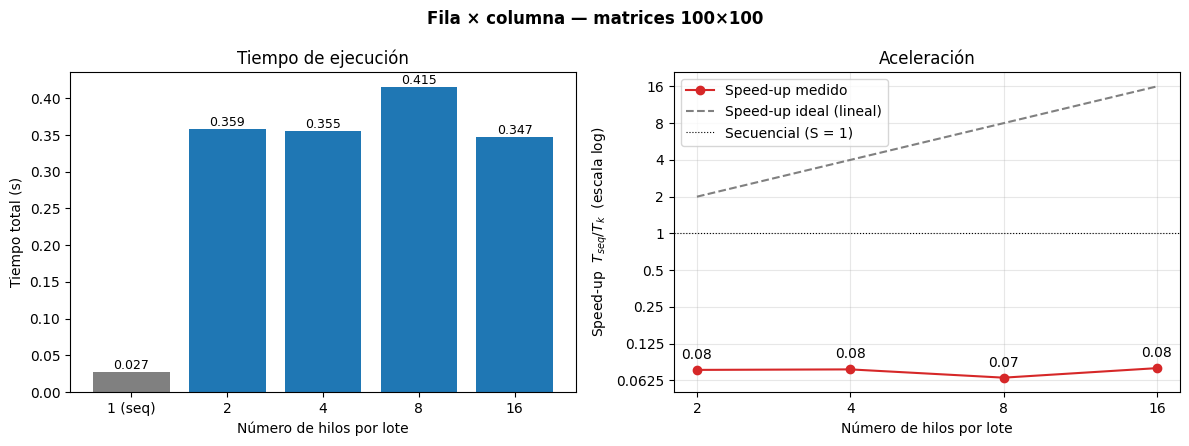

In [9]:
def graficar(tiempos, speedups, t_seq, titulo):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    # Tiempo total
    etiquetas = ["1 (seq)"] + [str(k) for k in HILOS]
    ax1.bar(etiquetas, [t_seq] + tiempos, color=["gray"] + ["tab:blue"] * len(HILOS))
    ax1.set_xlabel("Número de hilos por lote")
    ax1.set_ylabel("Tiempo total (s)")
    ax1.set_title("Tiempo de ejecución")
    for x, y in zip(etiquetas, [t_seq] + tiempos):
        ax1.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)

    # Speed-up
    ax2.plot(HILOS, speedups, "o-", label="Speed-up medido", color="tab:red")
    ax2.plot(HILOS, HILOS, "--", label="Speed-up ideal (lineal)", color="gray")
    ax2.axhline(1, color="black", lw=0.8, ls=":", label="Secuencial (S = 1)")
    for k, s in zip(HILOS, speedups):
        ax2.annotate(f"{s:.2f}", (k, s), textcoords="offset points", xytext=(0, 8), ha="center")
    ax2.set_xscale("log", base=2)
    ax2.set_yscale("log", base=2)   # escala log para ver a la vez el ideal y valores < 1
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax2.set_xticks(HILOS, [str(k) for k in HILOS])
    ax2.set_xlabel("Número de hilos por lote")
    ax2.set_ylabel("Speed-up  $T_{seq} / T_k$  (escala log)")
    ax2.set_title("Aceleración")
    ax2.legend()
    ax2.grid(alpha=0.3)

    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()

graficar(tiempos_fc, speedup_fc, t_seq_fc, f"Fila × columna — matrices {N}×{N}")

---
# Advertencia: variante con dos filas y dos columnas

Ahora la función recibe **dos filas** de $A$ y **dos columnas** de $B$, y calcula de una vez el bloque de $2 \times 2$:

$$\begin{bmatrix} C_{i,j} & C_{i,j+1} \\ C_{i+1,j} & C_{i+1,j+1} \end{bmatrix} =
\begin{bmatrix} f_1 \cdot c_1 & f_1 \cdot c_2 \\ f_2 \cdot c_1 & f_2 \cdot c_2 \end{bmatrix}$$

Cada hilo hace 4 productos punto en vez de 1, así que se necesitan $n^2/4$ hilos en lugar de $n^2$. Se repiten los puntos 1 a 5 y se comparan los resultados.

In [10]:
def multiplicar_dos_filas_dos_columnas(fila1, fila2, col1, col2, resultado, i, j):
    # Calcula el bloque 2x2 que empieza en (i, j)
    s11 = s12 = s21 = s22 = 0
    for a1, a2, b1, b2 in zip(fila1, fila2, col1, col2):
        s11 += a1 * b1
        s12 += a1 * b2
        s21 += a2 * b1
        s22 += a2 * b2
    resultado[i][j],     resultado[i][j + 1]     = s11, s12
    resultado[i + 1][j], resultado[i + 1][j + 1] = s21, s22


def multiplicar_secuencial_2x2(A, BT):
    n = len(A)
    C = [[0] * n for _ in range(n)]
    for i in range(0, n, 2):
        for j in range(0, n, 2):
            multiplicar_dos_filas_dos_columnas(A[i], A[i + 1], BT[j], BT[j + 1], C, i, j)
    return C


def multiplicar_con_hilos_2x2(A, BT, num_hilos):
    n = len(A)
    C = [[0] * n for _ in range(n)]
    tareas = [(i, j) for i in range(0, n, 2) for j in range(0, n, 2)]

    for inicio in range(0, len(tareas), num_hilos):
        lote = tareas[inicio:inicio + num_hilos]
        hilos = [
            threading.Thread(target=multiplicar_dos_filas_dos_columnas,
                             args=(A[i], A[i + 1], BT[j], BT[j + 1], C, i, j))
            for (i, j) in lote
        ]
        for h in hilos:
            h.start()
        for h in hilos:
            h.join()
    return C

In [11]:
assert np.array_equal(np.array(multiplicar_secuencial_2x2(A, BT)), C_referencia)
for k in HILOS:
    assert np.array_equal(np.array(multiplicar_con_hilos_2x2(A, BT, k)), C_referencia)
print("Variante 2 filas × 2 columnas: todos los resultados coinciden con NumPy ✔")

Variante 2 filas × 2 columnas: todos los resultados coinciden con NumPy ✔


In [12]:
t_seq_2x2 = medir(multiplicar_secuencial_2x2, A, BT)
tiempos_2x2 = [medir(multiplicar_con_hilos_2x2, A, BT, k) for k in HILOS]
speedup_2x2 = [t_seq_2x2 / t for t in tiempos_2x2]

tabla_resultados(t_seq_2x2, tiempos_2x2,
                 f"2 filas × 2 columnas  (N = {N}, {N*N//4} hilos en total por ejecución)")

2 filas × 2 columnas  (N = 100, 2500 hilos en total por ejecución)
  Hilos |  Tiempo (s) |  Speed-up | Eficiencia
-----------------------------------------------
1 (seq) |      0.0248 |     1.000 |      1.000
      2 |      0.1487 |     0.167 |      0.083
      4 |      0.1192 |     0.208 |      0.052
      8 |      0.0962 |     0.257 |      0.032
     16 |      0.1170 |     0.212 |      0.013


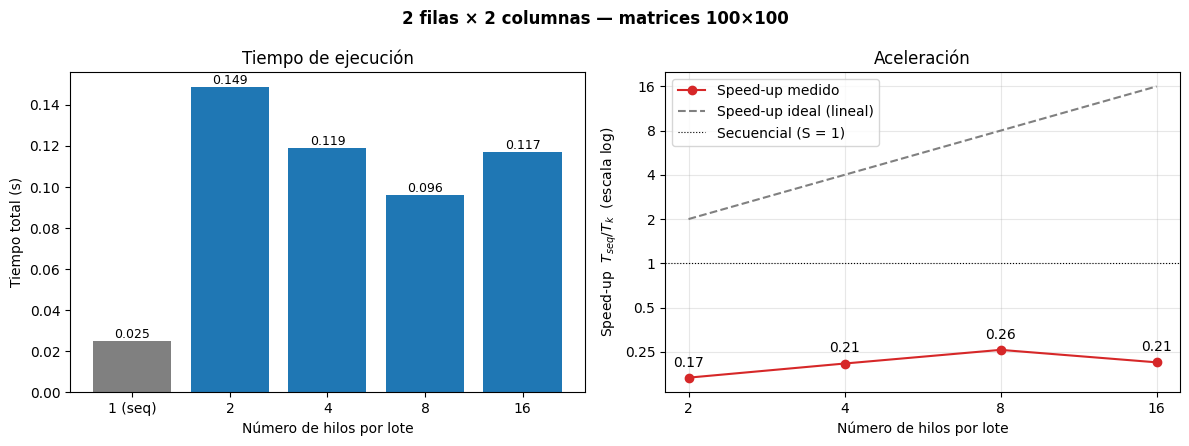

In [13]:
graficar(tiempos_2x2, speedup_2x2, t_seq_2x2, f"2 filas × 2 columnas — matrices {N}×{N}")

## Comparación de las dos variantes

In [14]:
print(f"{'Hilos':>6} | {'T fila×col (s)':>15} | {'T 2×2 (s)':>10} | {'S fila×col':>10} | {'S 2×2':>7} | {'S 2×2 vs fila×col':>18}")
print("-" * 82)
print(f"{'seq':>6} | {t_seq_fc:>15.4f} | {t_seq_2x2:>10.4f} | {1:>10.3f} | {1:>7.3f} | {t_seq_fc / t_seq_2x2:>18.3f}")
for k, t1, t2, s1, s2 in zip(HILOS, tiempos_fc, tiempos_2x2, speedup_fc, speedup_2x2):
    print(f"{k:>6} | {t1:>15.4f} | {t2:>10.4f} | {s1:>10.3f} | {s2:>7.3f} | {t1 / t2:>18.3f}")
print("\nÚltima columna: cuántas veces más rápida es la variante 2×2 que la de fila×columna con el mismo número de hilos.")

 Hilos |  T fila×col (s) |  T 2×2 (s) | S fila×col |   S 2×2 |  S 2×2 vs fila×col
----------------------------------------------------------------------------------
   seq |          0.0274 |     0.0248 |      1.000 |   1.000 |              1.105
     2 |          0.3586 |     0.1487 |      0.076 |   0.167 |              2.412
     4 |          0.3553 |     0.1192 |      0.077 |   0.208 |              2.981
     8 |          0.4152 |     0.0962 |      0.066 |   0.257 |              4.316
    16 |          0.3469 |     0.1170 |      0.079 |   0.212 |              2.966

Última columna: cuántas veces más rápida es la variante 2×2 que la de fila×columna con el mismo número de hilos.


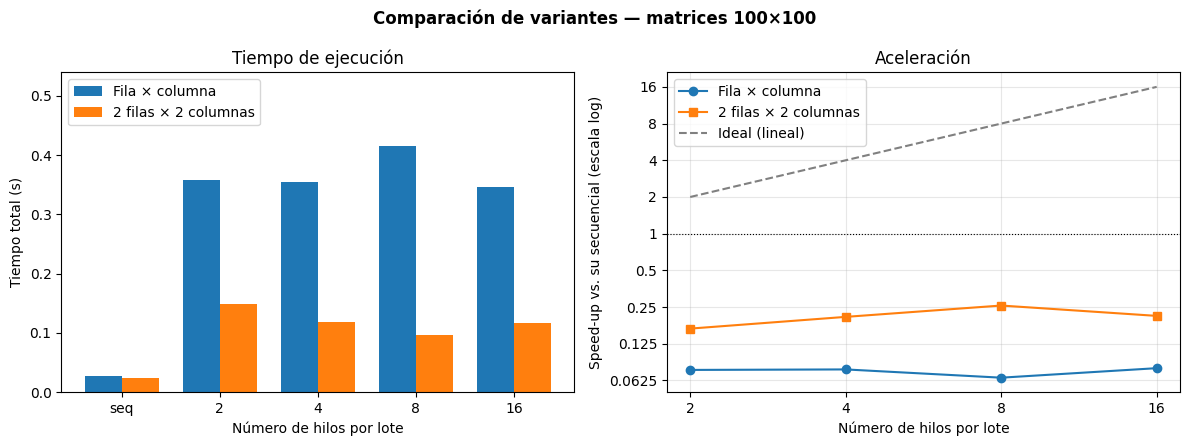

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(HILOS) + 1)
ancho = 0.38
etiquetas = ["seq"] + [str(k) for k in HILOS]

ax1.bar(x - ancho/2, [t_seq_fc] + tiempos_fc, ancho, label="Fila × columna", color="tab:blue")
ax1.bar(x + ancho/2, [t_seq_2x2] + tiempos_2x2, ancho, label="2 filas × 2 columnas", color="tab:orange")
ax1.set_xticks(x, etiquetas)
ax1.set_xlabel("Número de hilos por lote")
ax1.set_ylabel("Tiempo total (s)")
ax1.set_title("Tiempo de ejecución")
ax1.set_ylim(top=max([t_seq_fc] + tiempos_fc + [t_seq_2x2] + tiempos_2x2) * 1.3)
ax1.legend(loc="upper left")

ax2.plot(HILOS, speedup_fc, "o-", label="Fila × columna", color="tab:blue")
ax2.plot(HILOS, speedup_2x2, "s-", label="2 filas × 2 columnas", color="tab:orange")
ax2.plot(HILOS, HILOS, "--", color="gray", label="Ideal (lineal)")
ax2.axhline(1, color="black", lw=0.8, ls=":")
ax2.set_xscale("log", base=2)
ax2.set_yscale("log", base=2)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax2.set_xticks(HILOS, [str(k) for k in HILOS])
ax2.set_xlabel("Número de hilos por lote")
ax2.set_ylabel("Speed-up vs. su secuencial (escala log)")
ax2.set_title("Aceleración")
ax2.legend()
ax2.grid(alpha=0.3)

fig.suptitle(f"Comparación de variantes — matrices {N}×{N}", fontweight="bold")
plt.tight_layout()
plt.show()

## Análisis

**¿Por qué el speed-up no es lineal (ni siquiera mayor que 1)?** Dos razones se suman:

1. **El GIL de Python.** En CPython estándar el *Global Interpreter Lock* deja que solo un hilo ejecute bytecode de Python a la vez. Los hilos se turnan pero no corren en paralelo en varios núcleos, así que para un trabajo puramente de cómputo (CPU-bound) como este no hay ganancia real. Los hilos de Python sí aceleran tareas de entrada/salida (red, disco), donde el hilo suelta el GIL mientras espera.
2. **El costo de crear hilos.** Crear, iniciar y hacer `join` de un hilo cuesta del orden de decenas de microsegundos, mientras que un producto punto de 100 elementos cuesta unos pocos microsegundos. Con la variante fila×columna se crean $N^2$ hilos, y la mayor parte del tiempo se va en administrarlos, no en multiplicar. Es un caso de **granularidad demasiado fina**.

**¿Qué cambia con 2 filas × 2 columnas?** Cada hilo hace 4 veces más trabajo útil y se crean 4 veces menos hilos. Por eso esta variante es claramente más rápida que la de fila×columna con el mismo número de hilos: se paga menos sobrecosto por cada operación. En la versión secuencial, en cambio, las dos hacen exactamente las mismas multiplicaciones y sus tiempos son parecidos; la diferencia aparece solo cuando entran los hilos. Es el mismo principio que usan las implementaciones reales de multiplicación de matrices (multiplicación por bloques o *tiling*): agrupar trabajo para amortizar el costo de coordinación.

**¿Más hilos por lote ayuda?** Lanzar lotes más grandes reduce el número de esperas (`join`) entre lotes, pero no reduce el número total de hilos creados, que es lo que domina. Por eso las diferencias entre 2, 4, 8 y 16 hilos son pequeñas.

**¿Cómo obtener un speed-up real?** Con `multiprocessing` (procesos en vez de hilos, cada uno con su propio intérprete y su propio GIL), con Python 3.13+ en modo *free-threaded* (`python3.13t`), con Java (sus hilos sí corren en paralelo) o dándole a cada hilo un bloque grande de filas en lugar de un solo elemento.

> Los números de este notebook dependen de la máquina: conviene ejecutarlo en el propio computador y comentar los valores obtenidos.